# Compressor Health Clustering

## 1. Data Understanding and Exploratory Analysis

This notebook checks the supplied MetroPT-3 compressor data before any cleaning or modeling. It measures timestamp integrity, sampling behavior, missingness, duplicates, variable types, sensor distributions, and broad relationships. The original CSV is read without modification; the index-like column is retained only for diagnostics and excluded from sensor analysis.

**Run from the project root.** The notebook intentionally starts with empty outputs so that results are generated from your local dataset when you run it.

## 2. Import Libraries and Set Up the Analysis

Use a consistent dark charcoal plotting style with muted gridlines, bright readable text, and restrained blue, teal, and amber accents. This lowers glare while keeping important patterns easy to distinguish. The data path is resolved automatically by searching the current directory and its parent folders, so the notebook works when launched from either the project root or `notebooks/`.

In [7]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

DATA_RELATIVE_PATH = Path("data") / "raw" / "metropt+3+dataset" / "MetroPT3(AirCompressor).csv"
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / DATA_RELATIVE_PATH).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project data folder from the current directory. "
        "Open this notebook within the project checkout."
    )
DATA_PATH = PROJECT_ROOT / DATA_RELATIVE_PATH

PALETTE = {
    "blue": "#72B7F2",
    "teal": "#4FD1C5",
    "amber": "#F6C177",
    "red": "#F28B82",
    "gray": "#AAB6C2",
    "figure_bg": "#151B23",
    "axes_bg": "#202833",
    "text": "#E6EDF3",
    "muted_text": "#B8C4D0",
    "grid": "#3B4653",
}
sns.set_theme(style="darkgrid", context="notebook", font="DejaVu Sans", font_scale=1.0)
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 120,
    "figure.facecolor": PALETTE["figure_bg"],
    "savefig.facecolor": PALETTE["figure_bg"],
    "axes.facecolor": PALETTE["axes_bg"],
    "axes.edgecolor": PALETTE["grid"],
    "axes.labelcolor": PALETTE["text"],
    "axes.titlecolor": PALETTE["text"],
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": PALETTE["muted_text"],
    "ytick.color": PALETTE["muted_text"],
    "text.color": PALETTE["text"],
    "grid.color": PALETTE["grid"],
    "grid.alpha": 0.55,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print(f"Dataset: {DATA_PATH}")

Dataset: c:\Projects_Tracking\Compressor_Health_Clustering\data\raw\metropt+3+dataset\MetroPT3(AirCompressor).csv


## 3. Load the Data and Confirm Its Structure

The file is about 218 MB, so this notebook loads it once and avoids making unnecessary full-size copies. Parse timestamps explicitly and preserve the source row order for chronology checks.

In [8]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])

print(f"Rows: {len(df):,} | Columns: {df.shape[1]:,}")
print(f"In-memory size: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MiB")
display(df.head())
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "unique_values": df.nunique(dropna=True),
}).rename_axis("column"))

Rows: 1,516,948 | Columns: 17
In-memory size: 196.7 MiB


,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


,dtype,non_null,unique_values
column,,,
Unnamed: 0,int64,1516948,1516948
timestamp,datetime64[us],1516948,1516948
TP2,float64,1516948,5257
TP3,float64,1516948,3683
H1,float64,1516948,2665
DV_pressure,float64,1516948,2257
Reservoirs,float64,1516948,3682
Oil_temperature,float64,1516948,2462
Motor_current,float64,1516948,1809


## 4. Check Timestamp Order, Uniqueness, and Sampling Intervals

The interval distribution shows whether the nominal cadence is regular and how large gaps or timestamp jitter may affect window construction. We preserve all rows here; this is a diagnostic, not a cleaning step.

,value
invalid_timestamps,0
duplicate_timestamps,0
out_of_order_steps,0
nonpositive_intervals,0
start,2020-02-01 00:00:00
end,2020-09-01 03:59:50
median_interval_seconds,10.0
p95_interval_seconds,10.0
maximum_interval_seconds,172918.0
gaps_over_30_seconds,331


Largest timestamp gaps (inspect these before choosing feature windows):


,gap_start,gap_end,gap_seconds
0,2020-04-25 01:10:51,2020-04-27 01:12:49,172918.0
1,2020-06-27 10:53:07,2020-06-28 23:07:43,130476.0
2,2020-02-28 23:57:08,2020-03-01 04:00:09,100981.0
3,2020-08-04 07:42:28,2020-08-05 08:23:01,88833.0
4,2020-05-24 00:39:23,2020-05-25 01:14:14,88491.0
5,2020-07-07 15:24:51,2020-07-08 15:20:51,86160.0
6,2020-08-22 19:11:44,2020-08-23 18:51:01,85157.0
7,2020-05-10 00:31:17,2020-05-10 22:48:58,80261.0
8,2020-06-07 14:19:39,2020-06-08 11:48:04,77305.0
9,2020-04-01 13:15:40,2020-04-02 09:59:17,74617.0


,count,percent_of_steps
timestamp,,
10.0,1337521,88.17
9.0,128277,8.46
12.0,38321,2.53
13.0,7988,0.53
11.0,4471,0.29
21.0,10,0.00
19.0,5,0.00
22.0,4,0.00
20.0,3,0.00


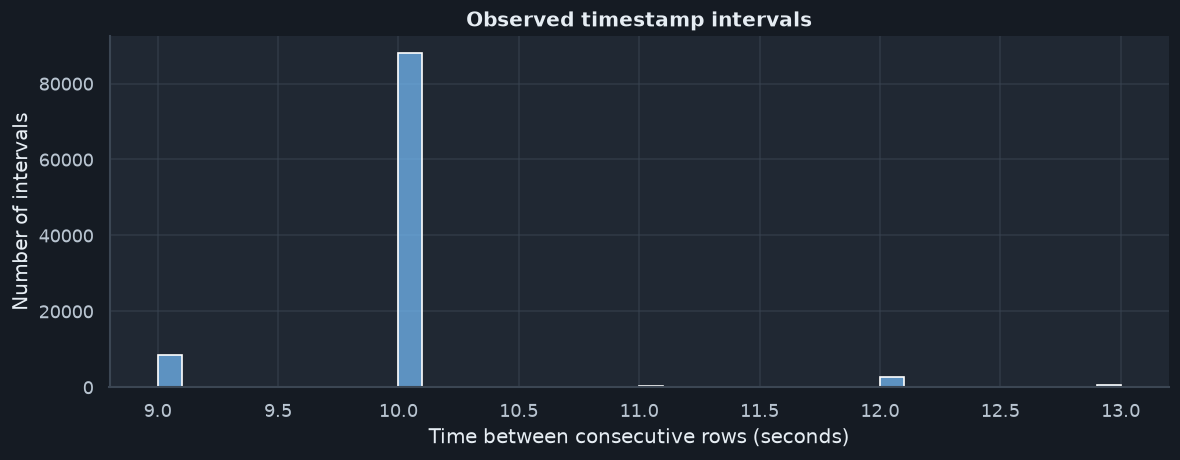

In [9]:
if not pd.api.types.is_datetime64_any_dtype(df["timestamp"]):
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

interval_s = df["timestamp"].diff().dt.total_seconds()
quality = pd.Series({
    "invalid_timestamps": int(df["timestamp"].isna().sum()),
    "duplicate_timestamps": int(df["timestamp"].duplicated().sum()),
    "out_of_order_steps": int((interval_s < 0).sum()),
    "nonpositive_intervals": int((interval_s <= 0).sum()),
    "start": df["timestamp"].min(),
    "end": df["timestamp"].max(),
    "median_interval_seconds": interval_s.median(),
    "p95_interval_seconds": interval_s.quantile(0.95),
    "maximum_interval_seconds": interval_s.max(),
    "gaps_over_30_seconds": int((interval_s > 30).sum()),
    "gaps_over_1_hour": int((interval_s > 3600).sum()),
})
display(quality.to_frame("value"))

gap_mask = interval_s > 30
if gap_mask.any():
    gap_report = pd.DataFrame({
        "gap_start": df.loc[gap_mask.index[gap_mask] - 1, "timestamp"].to_numpy(),
        "gap_end": df.loc[gap_mask, "timestamp"].to_numpy(),
        "gap_seconds": interval_s.loc[gap_mask].to_numpy(),
    }).sort_values("gap_seconds", ascending=False)
    print("Largest timestamp gaps (inspect these before choosing feature windows):")
    display(gap_report.head(10).reset_index(drop=True))

interval_counts = interval_s.value_counts().sort_index()
interval_table = pd.DataFrame({
    "count": interval_counts,
    "percent_of_steps": interval_counts / interval_s.notna().sum() * 100,
})
display(interval_table.sort_values("count", ascending=False).head(15).round(2))

fig, ax = plt.subplots(figsize=(10, 4))
plot_intervals = interval_s[(interval_s > 0) & (interval_s <= interval_s.quantile(0.999))]
plot_intervals = plot_intervals.sample(
    n=min(100_000, len(plot_intervals)), random_state=42
)
sns.histplot(plot_intervals, bins=40, color=PALETTE["blue"], ax=ax)
ax.set(title="Observed timestamp intervals", xlabel="Time between consecutive rows (seconds)", ylabel="Number of intervals")
fig.tight_layout()
plt.show()

**Interpretation prompt:** Note the dominant interval and the share of steps that differ from it. If the intervals are not consistently regular, later feature windows should be time-based and should not bridge long gaps blindly.

## 5. Assess Missing Values, Duplicate Rows, and the Index-Like Column

Summarize missingness and exact duplicate rows. The `Unnamed: 0` field appears to be a sequential source index; verify this before excluding it from subsequent analyses.

In [10]:
missing = df.isna().sum().rename("missing_count").to_frame()
missing["missing_percent"] = missing["missing_count"] / len(df) * 100
display(missing.sort_values("missing_count", ascending=False))
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

index_col = "Unnamed: 0" if "Unnamed: 0" in df.columns else None
if index_col:
    row_step = pd.to_numeric(df[index_col], errors="coerce").diff()
    display(pd.Series({
        "unique_values": df[index_col].nunique(dropna=True),
        "duplicate_values": int(df[index_col].duplicated().sum()),
        "most_common_step": row_step.mode().iloc[0] if not row_step.mode().empty else np.nan,
        "minimum_step": row_step.min(),
        "maximum_step": row_step.max(),
    }, name="source index diagnostic").to_frame())

,missing_count,missing_percent
Unnamed: 0,0,0.0
timestamp,0,0.0
TP2,0,0.0
TP3,0,0.0
H1,0,0.0
DV_pressure,0,0.0
Reservoirs,0,0.0
Oil_temperature,0,0.0
Motor_current,0,0.0
COMP,0,0.0


Exact duplicate rows: 0


,source index diagnostic
unique_values,1516948.0
duplicate_values,0.0
most_common_step,10.0
minimum_step,10.0
maximum_step,10.0


## 6. Separate Continuous Sensors from State-Like Signals

Use observed cardinality and value ranges as a first-pass description, not as a final domain classification. Several signals are numeric encodings of operating states; later feature selection will use the dataset documentation and observed behavior.

In [11]:
excluded_columns = {"timestamp"}
if index_col:
    excluded_columns.add(index_col)
sensor_columns = [c for c in df.columns if c not in excluded_columns and pd.api.types.is_numeric_dtype(df[c])]

profile = pd.DataFrame({
    "unique_values": df[sensor_columns].nunique(),
    "minimum": df[sensor_columns].min(),
    "median": df[sensor_columns].median(),
    "maximum": df[sensor_columns].max(),
    "mean": df[sensor_columns].mean(),
    "std": df[sensor_columns].std(),
}).sort_values("unique_values")
display(profile.round(3))

low_cardinality = profile.index[profile["unique_values"] <= 10].tolist()
print("Low-cardinality numeric signals (inspect as possible state indicators):")
print(low_cardinality)

,unique_values,minimum,median,maximum,mean,std
COMP,2,0.000,1.000,1.000,0.837,0.369
Caudal_impulses,2,0.000,1.000,1.000,0.937,0.243
Oil_level,2,0.000,1.000,1.000,0.904,0.294
Pressure_switch,2,0.000,1.000,1.000,0.991,0.092
LPS,2,0.000,0.000,1.000,0.003,0.058
MPG,2,0.000,1.000,1.000,0.833,0.373
Towers,2,0.000,1.000,1.000,0.920,0.272
DV_eletric,2,0.000,0.000,1.000,0.161,0.367
Motor_current,1809,0.020,0.045,9.295,2.050,2.302
DV_pressure,2257,-0.032,-0.020,9.844,0.056,0.382


Low-cardinality numeric signals (inspect as possible state indicators):
['COMP', 'Caudal_impulses', 'Oil_level', 'Pressure_switch', 'LPS', 'MPG', 'Towers', 'DV_eletric']


## 7. Inspect Sensor Distributions and Relationships

Distribution plots reveal skew, discrete levels, and extreme ranges that can influence distance-based clustering. The correlation heatmap is a screening tool for redundant continuous signals; correlations alone do not determine which sensors should be retained.

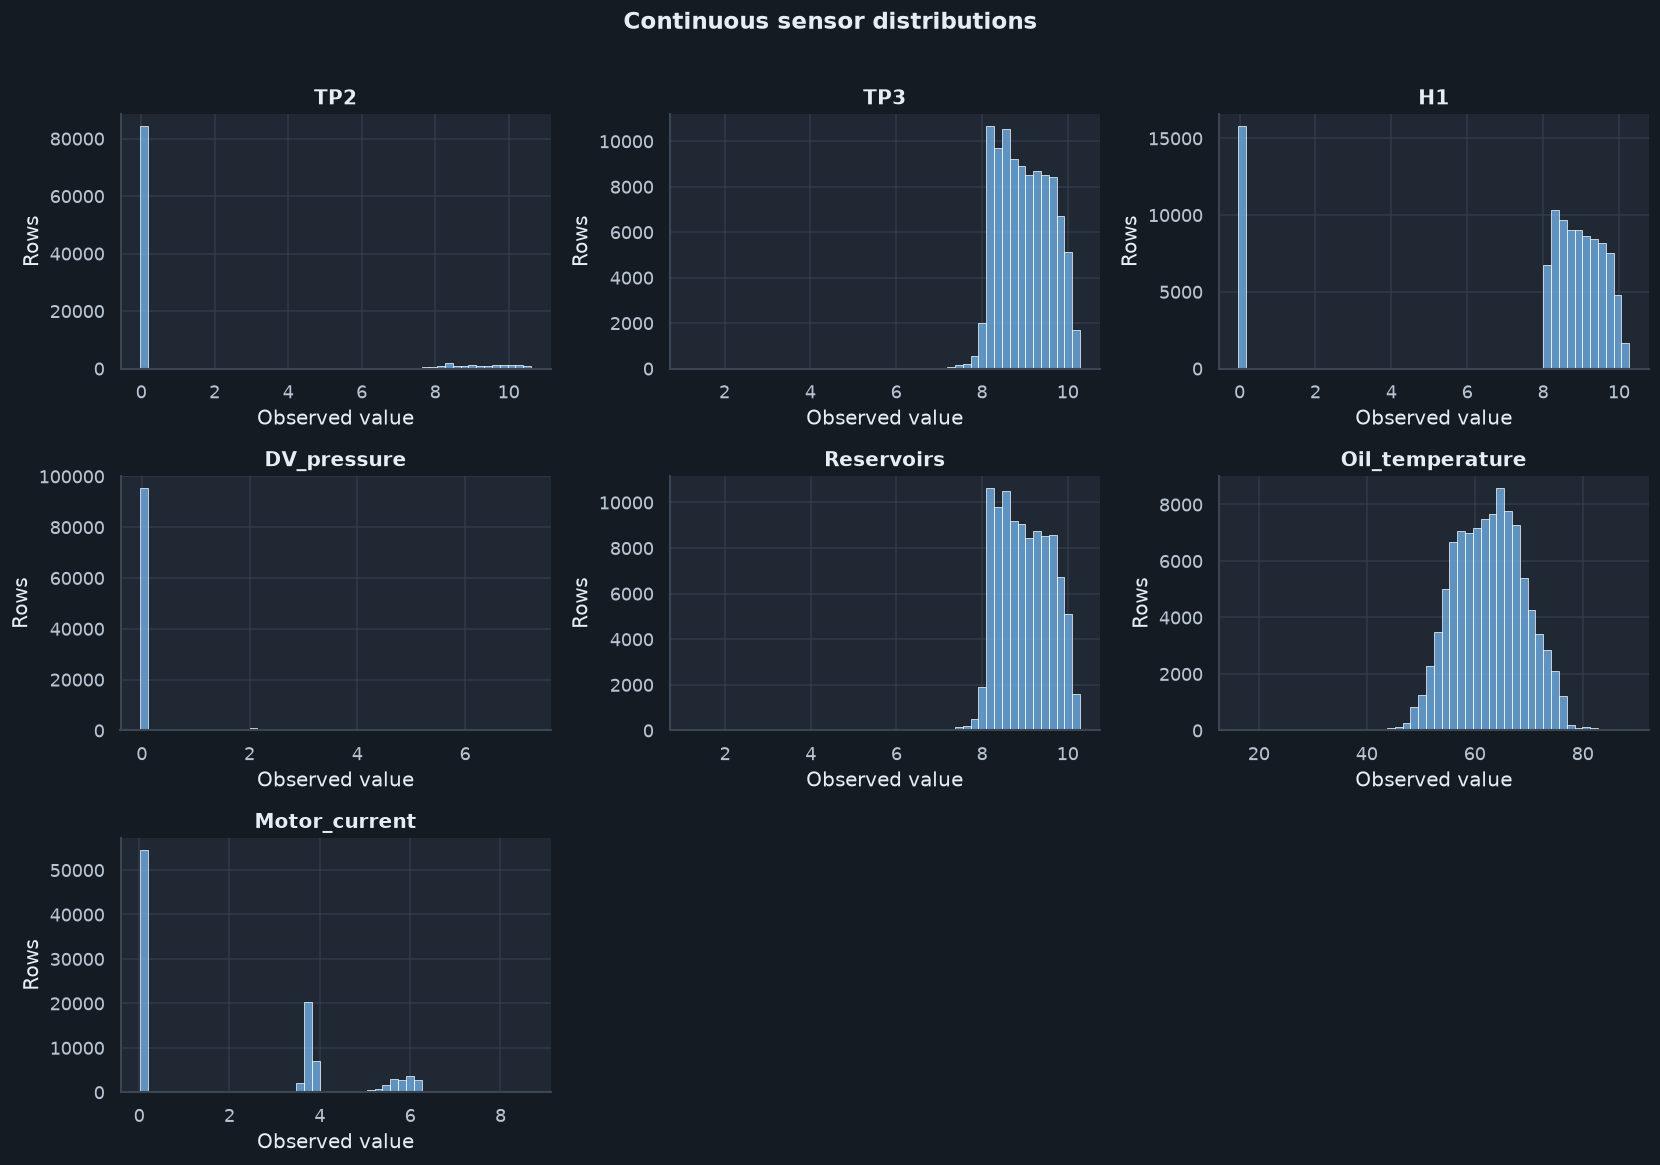

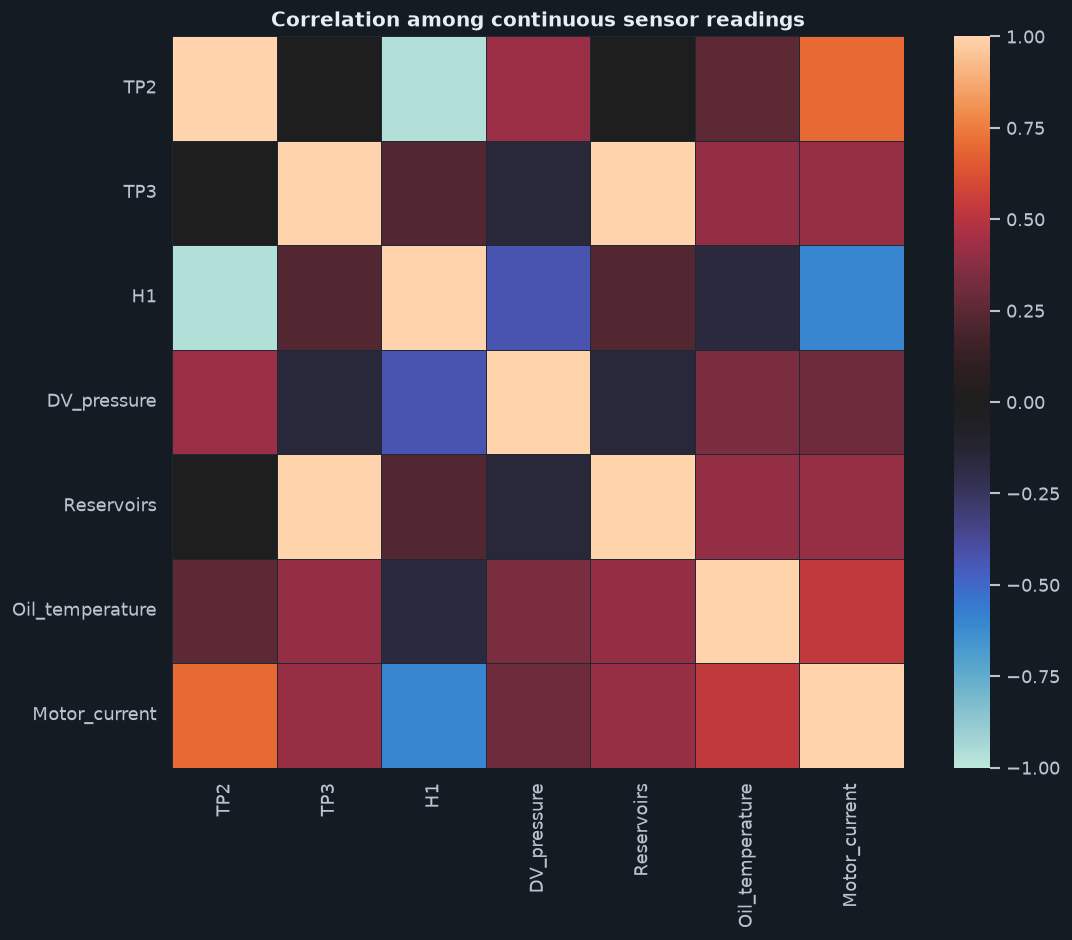

In [12]:
continuous_columns = [c for c in sensor_columns if c not in low_cardinality]
if continuous_columns:
    distribution_sample = df[continuous_columns].sample(
        n=min(100_000, len(df)), random_state=42
    )
    ncols = 3
    nrows = int(np.ceil(len(continuous_columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows))
    axes = np.asarray(axes).reshape(-1)
    for ax, column in zip(axes, continuous_columns):
        sns.histplot(distribution_sample[column], bins=50, color=PALETTE["blue"], ax=ax)
        ax.set_title(column)
        ax.set_xlabel("Observed value")
        ax.set_ylabel("Rows")
    for ax in axes[len(continuous_columns):]:
        ax.remove()
    fig.suptitle("Continuous sensor distributions", y=1.01, fontsize=14, fontweight="bold")
    fig.tight_layout()
    plt.show()

if len(continuous_columns) > 1:
    corr = df[continuous_columns].corr()
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(corr, cmap="icefire", center=0, vmin=-1, vmax=1, square=True, linewidths=0.3, linecolor=PALETTE["axes_bg"], ax=ax)
    ax.collections[0].colorbar.ax.tick_params(colors=PALETTE["muted_text"])
    ax.collections[0].colorbar.outline.set_edgecolor(PALETTE["grid"])
    ax.set_title("Correlation among continuous sensor readings")
    fig.tight_layout()
    plt.show()

## 8. View Chronological Sensor Trends Without Hiding Gaps

Plot hourly medians for a compact overview of key pressure and temperature signals. Resampling leaves empty hours as missing values, so lines break across multi-hour data gaps instead of connecting across unobserved periods. The separate gap table records shorter gaps as well.

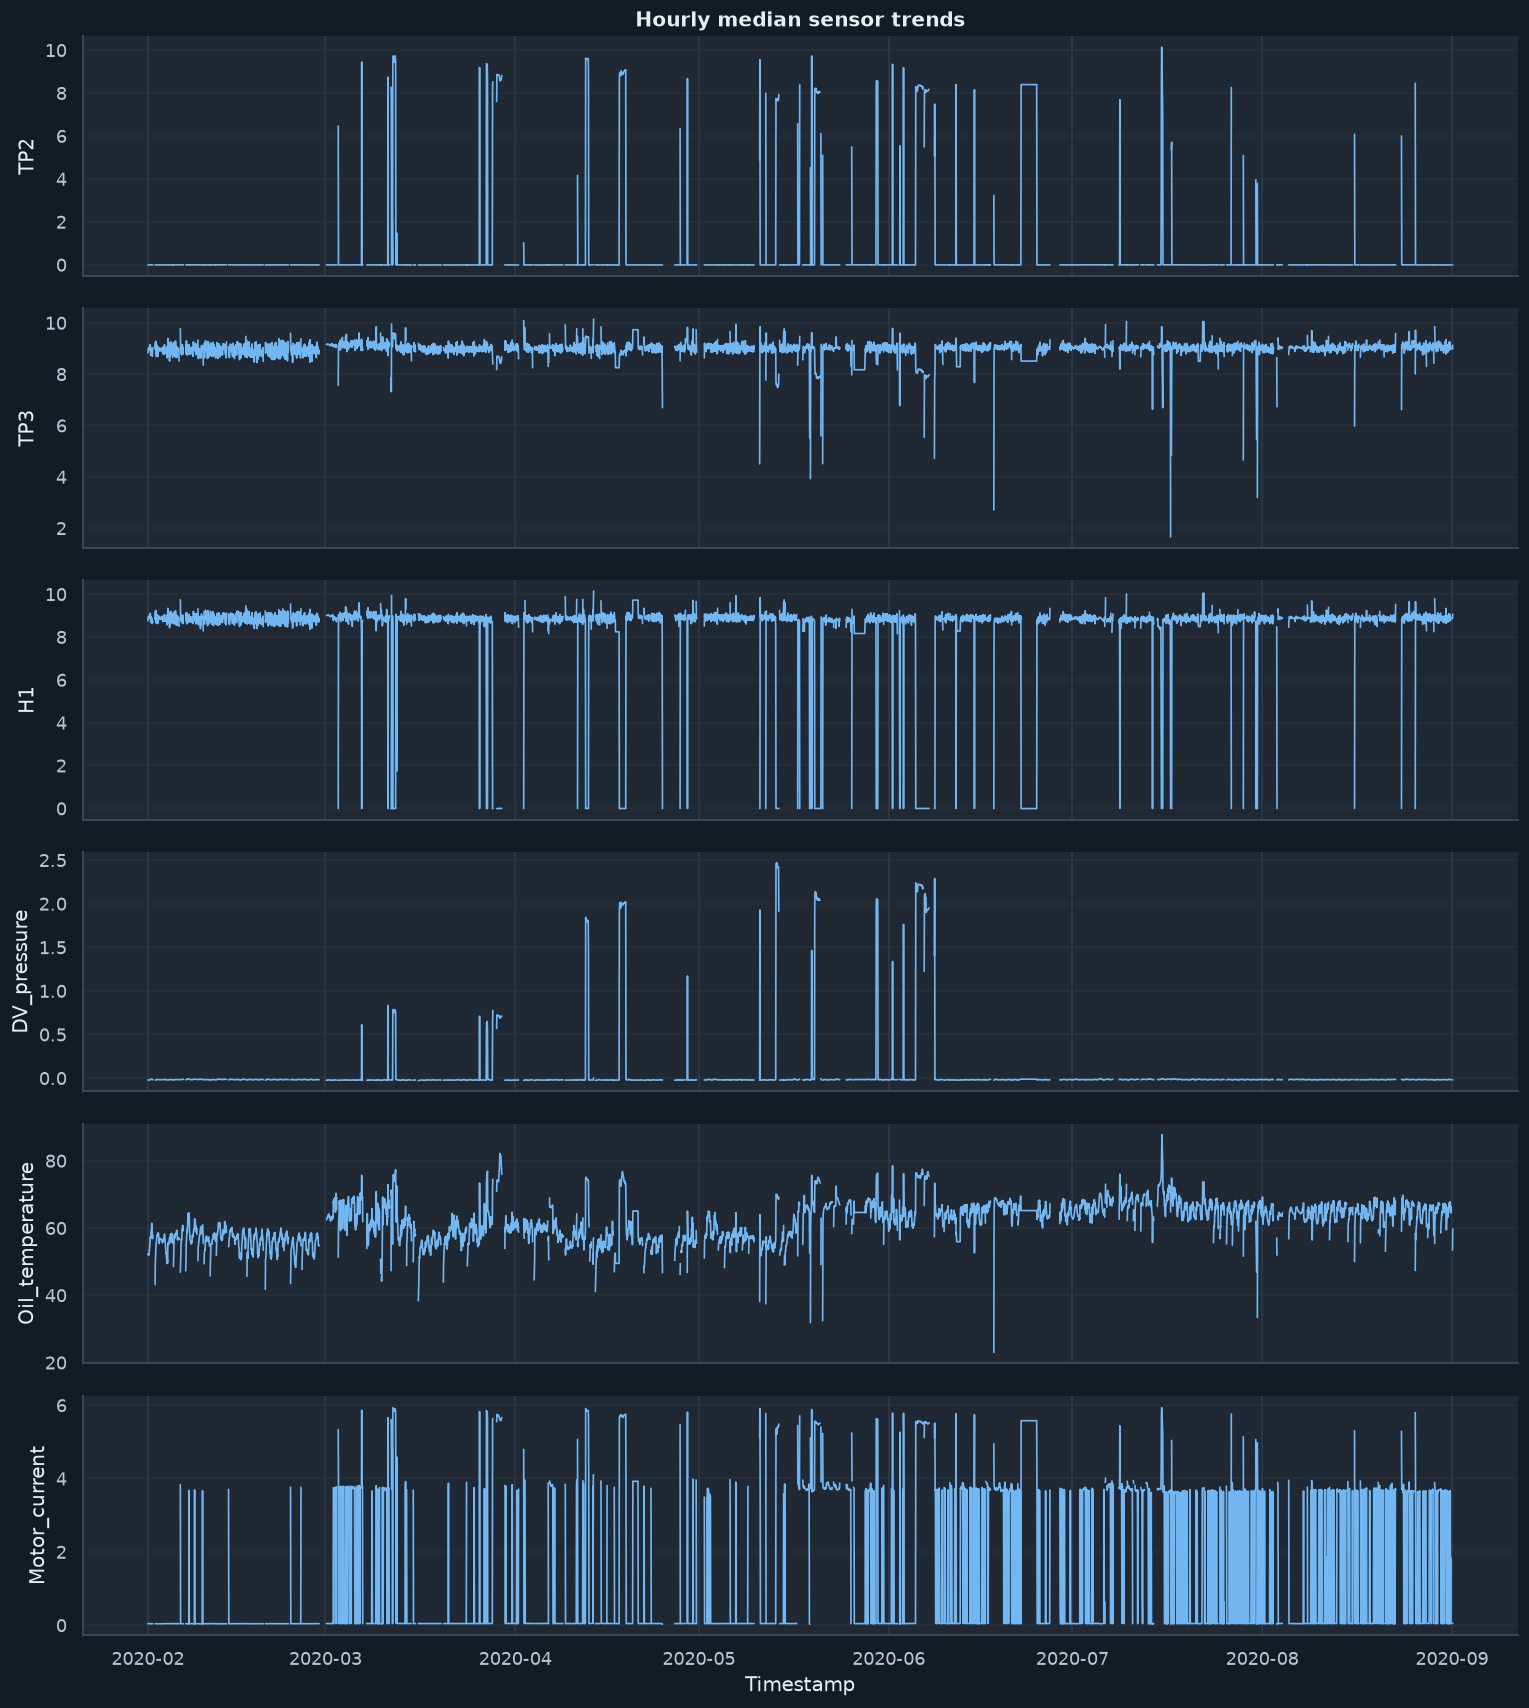

In [13]:
trend_candidates = [c for c in ["TP2", "TP3", "H1", "DV_pressure", "Oil_temperature", "Motor_current"] if c in sensor_columns]
trend = (
    df.set_index("timestamp")[trend_candidates]
      .resample("1h").median()
)

fig, axes = plt.subplots(len(trend_candidates), 1, figsize=(13, 2.4 * len(trend_candidates)), sharex=True)
if len(trend_candidates) == 1:
    axes = [axes]
for ax, column in zip(axes, trend_candidates):
    ax.plot(trend.index, trend[column], color=PALETTE["blue"], linewidth=1.0)
    ax.set_ylabel(column)
    ax.grid(axis="y", alpha=0.2)
axes[0].set_title("Hourly median sensor trends")
axes[-1].set_xlabel("Timestamp")
fig.tight_layout()
plt.show()

## 9. Findings and Limitations

### Findings from the supplied CSV

- The file contains **1,516,948 rows** and 17 columns: a sequential source index, a timestamp, and 15 sensor signals. The observed coverage runs from **2020-02-01 00:00:00** to **2020-09-01 03:59:50**.
- There are **no invalid, duplicate, or out-of-order timestamps**, no exact duplicate rows, and no missing values in the supplied columns. The source index increments by 10 every row and is not a sensor; exclude it from modeling.
- The median and 95th-percentile sampling intervals are both **10 seconds**. About **88.17%** of intervals are exactly 10 seconds; 9-second intervals account for 8.46%, and 12-second intervals for 2.53%. The dataset description says data were logged at 1 Hz, so the supplied CSV appears to have a coarser cadence than the documentation describes.
- Timestamp continuity still needs careful handling: **331 gaps exceed 30 seconds**, **160 exceed one hour**, and the largest is **48 hours, 1 minute, 58 seconds** (April 25-27). A clean row-level missingness table does not mean there are no periods without observations. Never interpolate or form windows across these gaps.
- The eight low-cardinality signals are binary in this file: `COMP`, `DV_eletric`, `Towers`, `MPG`, `LPS`, `Pressure_switch`, `Oil_level`, and `Caudal_impulses`. Treat them as state or event signals rather than continuous measurements.
- The histograms show strong concentrations near zero for `TP2` and `DV_pressure`, and a multi-modal distribution for `Motor_current`. These patterns may represent operating states; do not clip or remove them as outliers without a domain-based reason. `TP3` and `Reservoirs` have very similar distributions, and the correlation heatmap shows strong redundancy between them.
- In the hourly trends, `TP3` and `Reservoirs` remain mostly around 9 bar with short drops, while `TP2`, `H1`, and `DV_pressure` show repeated transitions. Oil temperature varies over the observation period and is generally higher in the middle months than at the start. Motor current switches among distinct operating levels. These are operating-pattern observations, not fault diagnoses.

### Implications for the next stage

Keep the original chronological order and raw readings. Use the 10-second observed cadence as the initial sampling reference, split processing at timestamp gaps, inspect operating-state dwell times, and compare candidate feature-window durations before finalizing a window size. Consider the near-redundant pressure signals during feature selection, but do not remove one until the later analysis documents that choice.

### Limitations

- The trend chart uses hourly medians to show the long-term pattern; brief transients are smoothed. Sensor histograms use a reproducible sample of up to 100,000 rows.
- The timestamp gaps indicate unobserved periods, but this notebook does not infer why they occurred.
- The dataset description lists reported air-leak/high-stress periods separately; the CSV has no row-level fault label. Those reports can support a later retrospective comparison, not a claim of prospective prediction. The description also has an internally inconsistent maintenance note for the May 29-30 event, which must be checked before validation.
- Clusters and unusual readings, if found later, will describe observed behavior. They will not by themselves confirm equipment faults or provide health probabilities.
